In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('Data/data.csv', sep=";")
df["Date"] = pd.to_datetime(df["Date"])
df.head()

/tmp/ipykernel_22076/1703537371.py:1: DtypeWarning: Columns (23: Ech. comm. Allemagne-Belgique (MW), 28: Gaz - Cogénération (MW)) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Data/data.csv', sep=";")


,Périmètre,Nature,Date,Heure,Date et Heure,Consommation (MW),Prévision J-1 (MW),Prévision J (MW),Fioul (MW),Charbon (MW),...,Gaz - TAC (MW),Gaz - Cogénération (MW),Gaz - CCG (MW),Gaz - Autres (MW),Hydraulique - Fil de l'eau + éclusée (MW),Hydraulique - Lacs (MW),Hydraulique - STEP turbinage (MW),Bioénergies - Déchets (MW),Bioénergies - Biomasse (MW),Bioénergies - Biogaz (MW)
0,France,Données consolidées,2026-06-30,23:45,2026-06-30T23:45:00+02:00,NaN,48050,48200,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,France,Données consolidées,2026-06-30,23:30,2026-06-30T23:30:00+02:00,48906.0,49100,49400,51.0,14.0,...,92.0,169.0,4744.0,46.0,3658.0,2910.0,2695.0,406.0,410.0,297.0
2,France,Données consolidées,2026-06-30,23:15,2026-06-30T23:15:00+02:00,NaN,49900,50300,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,France,Données consolidées,2026-06-30,23:00,2026-06-30T23:00:00+02:00,49944.0,50700,51200,51.0,14.0,...,95.0,178.0,4748.0,67.0,3697.0,2999.0,2918.0,410.0,409.0,300.0
4,France,Données consolidées,2026-06-30,22:45,2026-06-30T22:45:00+02:00,NaN,50000,50550,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:

df = pd.read_csv('data.csv', sep=";")
df["Date"] = pd.to_datetime(df["Date"])

#We remove the nans for the target value
df = df.dropna(subset=["Consommation (MW)"]).copy()

data = (
    df.groupby("Date")["Consommation (MW)"]
      .agg(list)
      .reset_index(name="Consumption")
)

#The dataframe is sorted to avoid training on future data
data = data.sort_values(["Date"])



conso = data["Consumption"]
#lag 1 is the data from yesterday, on which we do the regression to predict today's data
data["lag_1"] = conso.shift(1)
data= data.iloc[1:]
data= data.drop(["Date"], axis=1)

n = len(data)
cut_train = int(0.70 * n)
cut_val = int(0.85 * n)

data_train = data.iloc[:cut_train].copy()
data_val = data.iloc[cut_train:cut_val].copy()
data_test = data.iloc[cut_val:].copy()

target = "Consumption"

X_train = data_train.drop(columns=[target])
y_train = data_train[target]

X_test = data_test.drop(columns=[target])
y_test = data_test[target]

X_val= data_val.drop(columns=[target])
y_val= data_val[target]

print(X_val)

/tmp/ipykernel_107275/485567375.py:1: DtypeWarning: Columns (23: Ech. comm. Allemagne-Belgique (MW), 28: Gaz - Cogénération (MW)) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data.csv', sep=";")


                                                  lag_1
3706  [61571.0, 62540.0, 61006.0, 61044.0, 62644.0, ...
3707  [61296.0, 62154.0, 60460.0, 60277.0, 61627.0, ...
3708  [63702.0, 64540.0, 62955.0, 63016.0, 64356.0, ...
3709  [65291.0, 65911.0, 64050.0, 63616.0, 64678.0, ...
3710  [63327.0, 63537.0, 61370.0, 60437.0, 61163.0, ...
...                                                 ...
4495  [51843.0, 52441.0, 51115.0, 50497.0, 50988.0, ...
4496  [55921.0, 56600.0, 55391.0, 55235.0, 56021.0, ...
4497  [55320.0, 56068.0, 54815.0, 54727.0, 55435.0, ...
4498  [56299.0, 57062.0, 55877.0, 55813.0, 56630.0, ...
4499  [53623.0, 54295.0, 53111.0, 52971.0, 53632.0, ...

[794 rows x 1 columns]


In [68]:
data= data.iloc[1:]
data.head()

,Date,consumption,lag_1
1,2012-01-02,"[64902.0, 65929.0, 64030.0, 63756.0, 65332.0, ...","[55634.0, 56577.0, 54348.0, 53890.0, 54975.0, ..."
2,2012-01-03,"[65479.0, 66939.0, 64898.0, 64861.0, 66829.0, ...","[64902.0, 65929.0, 64030.0, 63756.0, 65332.0, ..."
3,2012-01-04,"[67376.0, 68550.0, 66878.0, 66808.0, 68726.0, ...","[65479.0, 66939.0, 64898.0, 64861.0, 66829.0, ..."
4,2012-01-05,"[66910.0, 68169.0, 66070.0, 66269.0, 68036.0, ...","[67376.0, 68550.0, 66878.0, 66808.0, 68726.0, ..."
5,2012-01-06,"[68818.0, 70058.0, 68082.0, 67591.0, 69141.0, ...","[66910.0, 68169.0, 66070.0, 66269.0, 68036.0, ..."


In [52]:
print(df.isna().mean().sort_values(ascending=False))

Bioénergies - Biogaz (MW)                    0.534563
Hydraulique - Lacs (MW)                      0.534563
Hydraulique - Fil de l'eau + éclusée (MW)    0.534563
Gaz - Autres (MW)                            0.534563
Gaz - CCG (MW)                               0.534563
Fioul - Cogénération (MW)                    0.534563
Fioul - Autres (MW)                          0.534563
Gaz - TAC (MW)                               0.534563
Fioul - TAC (MW)                             0.534563
Bioénergies - Déchets (MW)                   0.534563
Bioénergies - Biomasse (MW)                  0.534563
Hydraulique - STEP turbinage (MW)            0.534563
Bioénergies (MW)                             0.500000
Solaire (MW)                                 0.500000
Hydraulique (MW)                             0.500000
Eolien (MW)                                  0.500000
Nucléaire (MW)                               0.500000
Consommation (MW)                            0.500000
Fioul (MW)                  

In [53]:
df = df.dropna(subset=["Consommation (MW)"]).copy()

In [33]:
dates_brutes = data["Date et Heure"].copy()

data["Date et Heure"] = pd.to_datetime(
    dates_brutes,
    utc=True,
    errors="coerce"
)

print(data["Date et Heure"].head())
print(data["Date et Heure"].dtype)

1   2026-06-30 21:30:00+00:00
3   2026-06-30 21:00:00+00:00
5   2026-06-30 20:30:00+00:00
7   2026-06-30 20:00:00+00:00
9   2026-06-30 19:30:00+00:00
Name: Date et Heure, dtype: datetime64[us, UTC]
datetime64[us, UTC]


In [34]:
echecs = dates_brutes.notna() & df["Date et Heure"].isna()

print("Dates non converties :", echecs.sum())
print(dates_brutes[echecs].head())

Dates non converties : 0
Series([], Name: Date et Heure, dtype: str)


In [35]:
dates_locales = data["Date et Heure"].dt.tz_convert("Europe/Paris")

data["heure"] = (
    dates_locales.dt.hour
    + dates_locales.dt.minute / 60
)
data["jour_semaine"] = dates_locales.dt.dayofweek  # lundi=0, dimanche=6
data["mois"] = dates_locales.dt.month

In [36]:
data['jour_semaine'].unique()

array([1, 0, 6, 5, 4, 3, 2], dtype=int32)

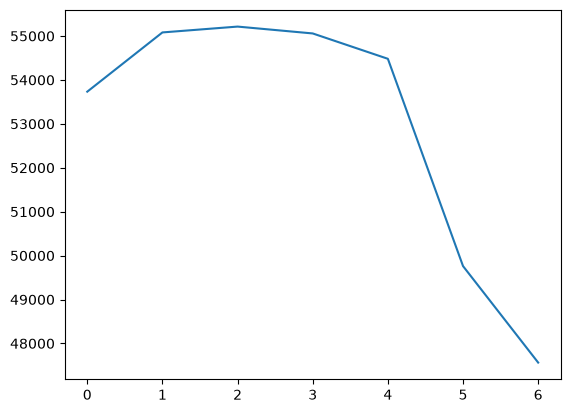

In [37]:
plt.plot([data.loc[data["jour_semaine"] == i, "Consommation (MW)"].mean() for i in range(0,7)])

In [38]:
data = data.sort_values("Date et Heure").reset_index(drop=True)

# Recréer cette variable après le tri
conso = data["Consommation (MW)"]

data["lag_1"] = conso.shift(1)
data["lag_48"] = conso.shift(48)
data["lag_336"] = conso.shift(336)
data["moyenne_24h"] = conso.shift(1).rolling(48).mean()

In [39]:
display(
    data.iloc[336:341][
        ["Date et Heure", "Consommation (MW)",
         "lag_1", "lag_48", "lag_336", "moyenne_24h"]
    ]
)

,Date et Heure,Consommation (MW),lag_1,lag_48,lag_336,moyenne_24h
336,2012-01-07 23:00:00+00:00,63684.0,63896.0,68419.0,58315.0,63160.562500
337,2012-01-07 23:30:00+00:00,62093.0,63684.0,66338.0,58315.0,63061.916667
338,2012-01-08 00:00:00+00:00,59359.0,62093.0,63504.0,56231.0,62973.479167
339,2012-01-08 00:30:00+00:00,59015.0,59359.0,62899.0,56075.0,62887.125000
340,2012-01-08 01:00:00+00:00,58290.0,59015.0,62078.0,55532.0,62806.208333


In [40]:
data= data.drop(["Date et Heure"], axis=1).iloc[336:]
shape= data.shape[0]


In [41]:
n = len(data)
cut_train = int(0.70 * n)
cut_val = int(0.85 * n)

data_train = data.iloc[:cut_train].copy()
data_val = data.iloc[cut_train:cut_val].copy()
data_test = data.iloc[cut_val:].copy()

In [42]:
target = "Consommation (MW)"

X_train = data_train.drop(columns=[target])
y_train = data_train[target]

X_test = data_test.drop(columns=[target])
y_test = data_test[target]

X_val= data_val.drop(columns=[target])
y_val= data_val[target]

In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [44]:
X_train

array([[-1.69629148,  1.50026319, -1.57071514, ...,  1.17823265,
         0.34101255,  0.81393942],
       [-1.62410471,  1.50026319, -1.57071514, ...,  1.00593731,
         0.34101255,  0.80499041],
       [-1.55191795,  1.50026319, -1.57071514, ...,  0.77129772,
         0.168574  ,  0.79696749],
       ...,
       [ 0.10837766,  0.50030535, -1.28285233, ...,  1.11506045,
         0.94529219,  0.97610637],
       [ 0.18056442,  0.50030535, -1.28285233, ...,  1.13335804,
         0.93321156,  0.97786404],
       [ 0.25275119,  0.50030535, -1.28285233, ...,  1.04344322,
         0.82638902,  0.97910197]], shape=(177676, 7))